In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("house_price_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975


\nColumn names:
['House_ID', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Location', 'Furnishing_Status', 'Parking_Available', 'Garage_Count', 'Lot_Size_sqft', 'Condition', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating', 'Has_Pool', 'Renovated', 'Price']


In [4]:
target = "Price"

X = df.drop(columns=[target, "House_ID"], errors="ignore")
y = df[target]

print("Input features:")
print(X.columns.tolist())
print("\\nTarget:", target)
print("\\nNumeric columns:", X.select_dtypes(include=np.number).columns.tolist())
print("Categorical columns:", X.select_dtypes(exclude=np.number).columns.tolist())

Input features:
['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Location', 'Furnishing_Status', 'Parking_Available', 'Garage_Count', 'Lot_Size_sqft', 'Condition', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating', 'Has_Pool', 'Renovated']
\nTarget: Price
\nNumeric columns: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical columns: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']


In [5]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Missing values in numerical features:")
print(X[numeric_features].isnull().sum())
print("\\nMissing values in categorical features:")
print(X[categorical_features].isnull().sum())

Missing values in numerical features:
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Garage_Count                   300
Lot_Size_sqft                  450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
dtype: int64
\nMissing values in categorical features:
Location             751
Furnishing_Status    901
Parking_Available    603
Condition            450
Has_Pool               0
Renovated              0
dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 12020
Testing records: 3005


In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [8]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully.")

Multiple Linear Regression model trained successfully.


In [9]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

display(comparison.head(10))

,Actual_Price,Predicted_Price
0,277576,312804.464532
1,312901,354861.141277
2,360400,389854.440025
3,603911,591332.147911
4,442974,450966.396756
5,155028,149120.477457
6,431076,411323.278617
7,362047,422213.004210
8,429965,411771.739516
9,415699,410235.175713


In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 30111.18
Mean Squared Error (MSE): 1774630840.94
Root Mean Squared Error (RMSE): 42126.37
R2 Score: 0.8965


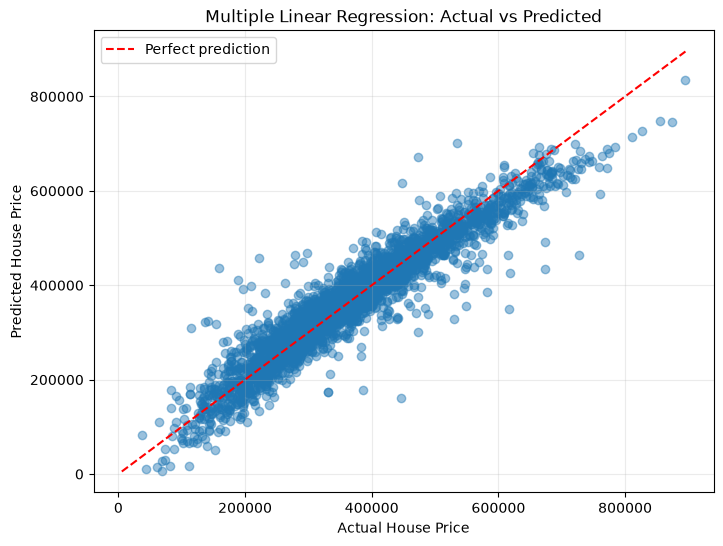

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.45)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value],
         color="red", linestyle="--", label="Perfect prediction")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [12]:
fitted_preprocessor = model.named_steps["preprocessor"]
regressor = model.named_steps["regressor"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": regressor.coef_
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values(
    "Absolute_Coefficient", ascending=False
)

print("Intercept:", round(regressor.intercept_, 2))
display(coefficients.head(15))

Intercept: -592904.99


,Feature,Coefficient,Absolute_Coefficient
28,cat__Location_downtown,74152.202625,74152.202625
11,cat__Location_DOWNTOWN,73421.196260,73421.196260
12,cat__Location_Downtown,72333.024957,72333.024957
10,cat__Location_ Downtown,71086.312800,71086.312800
29,cat__Location_greenfield,-70100.572302,70100.572302
13,cat__Location_Green field,-69717.266057,69717.266057
62,cat__Condition_POOR,-67708.992356,67708.992356
63,cat__Condition_Poor,-66721.282200,66721.282200
67,cat__Condition_poor,-65230.915963,65230.915963
56,cat__Condition_EXCELLENT,58620.476029,58620.476029


In [13]:
new_house = X.iloc[[0]].copy()

predicted_price = model.predict(new_house)[0]

print("Input house details:")
display(new_house)
print(f"Predicted house price: {predicted_price:,.2f}")

Input house details:


,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated
0,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no


Predicted house price: 264,630.44
